# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
 - **`/datasets/plans.csv`**
 - **`/datasets/users_latam.csv`**
 - **`/datasets/usage.csv`**
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos. 

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Diagnóstico de valores nulos. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico:**

*`users` (4,000 filas):*
- `city`: 469 nulos (11.72%). Está en el rango 5–30%, así que se investiga: es una variable categórica y no hay forma confiable de adivinar la ciudad, por lo que **la dejo como nulo** (más adelante se suman los `"?"`).
- `churn_date`: 3,534 nulos (88.35%). Supera el 80–90%, pero aquí el nulo tiene significado: el cliente **no se ha dado de baja**. **No la elimino ni la imputo**; la ignoro para el análisis de uso y solo uso si está vacía o no.
- El resto de columnas (`user_id`, `first_name`, `last_name`, `age`, `reg_date`, `plan`) no tiene nulos.

*`usage` (40,000 filas):*
- `date`: 50 nulos (0.12%). Es menos del 5% y la fecha no se usa para los conteos por usuario, así que **los dejo como nulos**.
- `duration`: 22,076 nulos (55.19%) y `length`: 17,896 nulos (44.74%). Proporciones altas, pero sospecho que son **nulos estructurales**: una llamada no tiene longitud de texto y un mensaje no tiene duración. Lo confirmo en el paso 3.2 antes de decidir; por ahora **no elimino ni imputo**.
- `id`, `user_id` y `type` no tienen nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` va de 10000 a 13999 con 4,000 valores: es un identificador consecutivo, sin duplicados y sin valores raros. No requiere acción.
- La columna `age` tiene un mínimo de **-999**, que es imposible para una edad: es un **sentinel**. Aparece en **55 filas (1.38%)**. Por eso la media (33.74) y la desviación estándar (123.23) salen distorsionadas. Sin el sentinel, las edades válidas van de 18 a 79 años.

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son identificadores: `id` va de 1 a 40,000 (uno por evento, sin duplicados) y `user_id` va de 10000 a 13999, el mismo rango que `users`. No requieren acción.
- Las columnas `duration` y `length` no tienen valores negativos. `duration` (minutos de llamada) tiene mediana de 3.5 y percentil 75 de 6.99, pero un máximo de **120**. `length` (caracteres del mensaje) tiene mediana de 50 y percentil 75 de 64, pero un máximo de **1,490**. Ese máximo se repite **exactamente 30 veces en cada columna**, y el siguiente valor más alto es mucho menor (46.98 minutos y 125 caracteres). Parecen valores extremos cargados artificialmente: los reviso en la sección de outliers (paso 5).
- También hay 15 llamadas con `duration` = 0 y 133 mensajes con `length` = 0. Son posibles (llamadas no contestadas o mensajes vacíos), así que no los trato como error.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene 6 ciudades válidas (Bogotá 808, CDMX 730, Medellín 616, GDL 450, Cali 424 y MTY 407), 469 nulos y **96 filas con `"?"`**, que es un **sentinel** de ciudad desconocida. Lo convierto a nulo.
- La columna `plan` solo tiene dos valores válidos: **`Basico`** (2,595 usuarios, sin tilde) y **`Premium`** (1,405). No hay errores de escritura ni nulos.

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` solo tiene dos valores válidos: `text` (22,092 eventos, 55.23%) y `call` (17,908 eventos, 44.77%). No hay sentinels ni nulos. Estas proporciones coinciden casi exactamente con los nulos de `duration` (55.19%) y `length` (44.74%), lo que refuerza que esos nulos dependen del tipo de evento.


---
✍️ **Comentario**: Diagnóstico de valores inválidos y sentinels. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**
- ¿En qué columnas encontraste valores inválidos o sentinels?
- ¿Qué acción tomarías?

**Diagnóstico:**
- `users['age']`: sentinel **-999** en 55 filas (1.38%). **Acción:** reemplazarlo por la mediana de las edades válidas. Son pocos casos y la mediana no se ve afectada por valores extremos.
- `users['city']`: sentinel **`"?"`** en 96 filas (2.40%). **Acción:** convertirlo a `pd.NA`, porque no se puede saber la ciudad real. Así `city` queda con 565 nulos (14.13%).
- `usage['duration']` = 120 y `usage['length']` = 1,490: 30 registros cada uno, muy lejos del resto de los datos. Además, 16 de los `duration` = 120 están en mensajes y 12 de los `length` = 1,490 están en llamadas, lo cual no tiene lógica. **Acción:** no los modifico en la limpieza básica (la plantilla no lo pide), pero los documento y los evalúo en el paso 5 (outliers).
- `plan` y `type` están limpias.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, la conversión no generó fechas inválidas (0 `NaT`). Los años válidos son 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero hay **40 registros (1.0%) con año 2026**. Todos tienen la misma fecha, 2026-05-10, lo cual es imposible porque los datos llegan hasta 2024 y parece un valor por defecto mal cargado. No hay años muy viejos ni negativos.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, los 39,950 eventos con fecha son de **2024** (de enero a junio de 2024). Los otros 50 (0.12%) ya venían vacíos en el archivo original; no son errores de conversión. No hay fechas fuera de rango.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: Diagnóstico e **acción recomendada** para cada caso:

**Fechas fuera de rango**
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico:**
- `reg_date`: sí, **40 fechas en 2026** (1.0% de los usuarios), todas el 2026-05-10. No hay años muy viejos ni negativos. **Acción:** marcarlas como nulas. No las elimino porque esos 40 usuarios tienen edad, plan y uso válidos, y perderlos sesgaría los conteos.
- `date` (usage): todas las fechas están dentro de 2024 (enero a junio) y solo hay 50 nulos que ya venían del archivo (0.12%). **Acción:** ninguna, porque no hay fechas fuera de rango.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
# Primero convierto -999 en NaN para que el sentinel no afecte la mediana
users['age'] = users['age'].replace(-999, np.nan)
age_mediana = users['age'].median()   # mediana solo de edades válidas
users['age'] = users['age'].fillna(age_mediana).astype(int)
print('Mediana usada:', age_mediana)

# Verificar cambios
users['age'].describe()

Mediana usada: 48.0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print('Filas con "?":', (users['city'] == '?').sum())
print('Nulos en city:', users['city'].isna().sum())

Filas con "?": 0
Nulos en city: 565


In [22]:
# Marcar fechas futuras como NA para reg_date
# En columnas de fecha, el nulo se guarda como NaT (equivalente a pd.NA para fechas)
users['reg_date'] = users['reg_date'].mask(users['reg_date'].dt.year > 2024)

# Verificar cambios
print('Fechas posteriores a 2024:', (users['reg_date'].dt.year > 2024).sum())
print('Nulos en reg_date:', users['reg_date'].isna().sum())
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

Fechas posteriores a 2024: 0
Nulos en reg_date: 40


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.
 Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`:**
- `duration` falta en el **0%** de las llamadas y en el **99.93%** de los mensajes.
- `length` falta en el **0%** de los mensajes y en el **99.93%** de las llamadas.
- Los nulos dependen totalmente de `type`, así que son **MAR**: es lógico que un mensaje no tenga duración ni una llamada longitud de texto. **Decisión:** dejarlos como nulos. Imputarlos crearía minutos o caracteres que nunca existieron, y eliminarlos borraría el 100% de las filas.
- El 0.07% que sí tiene valor en la columna "equivocada" son los 16 mensajes con `duration` = 120 y las 12 llamadas con `length` = 1,490 que vimos en 2.2. Son registros incoherentes y los tengo en cuenta al analizar outliers.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes
- número total de llamadas
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:
- `cant_mensajes`
- `cant_llamadas`
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text': 'sum',
                                          'is_call': 'sum',
                                          'duration': 'sum'}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes',
                                      'is_call': 'cant_llamadas',
                                      'duration': 'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
# how='left' conserva a todos los usuarios, aunque no tengan actividad registrada
user_profile = users.merge(usage_agg, on='user_id', how='left')

columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print('Usuarios sin actividad:', user_profile['cant_mensajes'].isna().sum())

# Un usuario sin registros en usage no hizo llamadas ni envió mensajes: su uso real es 0
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)
user_profile[['cant_mensajes', 'cant_llamadas']] = user_profile[['cant_mensajes', 'cant_llamadas']].astype(int)

print(user_profile.shape)
user_profile.head(5)

Usuarios sin actividad: 1
(4000, 11)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


**Nota sobre el merge:** `usage` tiene actividad de 3,999 usuarios y `users` tiene 4,000. Con `how='left'` se conservan los 4,000. El único usuario sin registros (`user_id` 11082) quedaba con `NaN` en los tres conteos, y los **rellené con 0** porque no tener eventos significa 0 mensajes, 0 llamadas y 0 minutos. Si se dejaran en `NaN`, ese usuario quedaría mal clasificado en la segmentación del paso 6.

**Unidad de `duration`:** viene en **minutos**. La mediana por llamada es de 3.5 y el percentil 75 de 6.97, lo cual es lógico para una llamada en minutos; en segundos serían llamadas de 3 segundos. Por eso la columna se llama `cant_minutos_llamada`.

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

**Resumen (enero a junio de 2024):**
- `age`: media de 48.14 y mediana de 48; va de 18 a 79 años. Después de la limpieza ya no hay valores imposibles.
- `cant_mensajes`: mediana de 5 mensajes por usuario (media 5.52); va de 0 a 17.
- `cant_llamadas`: mediana de 4 llamadas (media 4.48); va de 0 a 15.
- `cant_minutos_llamada`: mediana de 19.78 minutos y media de 23.31; el máximo es 155.69. Que la media sea mayor que la mediana anticipa un sesgo a la derecha.
- `plan`: el **64.88%** de los usuarios tiene plan **Basico** y el **35.12%** tiene **Premium**.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**
Graficar **histogramas** para las siguientes columnas:
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:
- "Dentro del plan Premium, hay mayor proporción de..."
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes." o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

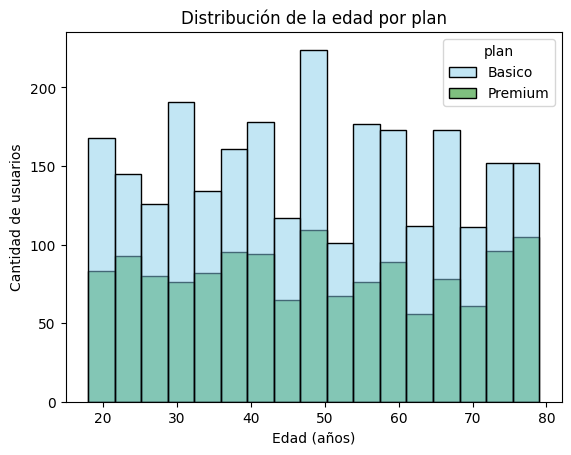

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **aproximadamente simétrica y casi uniforme**: hay usuarios de 18 a 79 años con frecuencias parecidas (asimetría ≈ 0.05; media 48.14 y mediana 48).
- Hay un pico en **48 años** (127 usuarios), causado por la imputación de los 55 `-999` con la mediana. Es un efecto de la limpieza, no un comportamiento real.
- **No existe ningún patrón por plan:** Basico y Premium tienen la misma forma y la misma mediana (48). Las barras de Basico se ven más altas solo porque tiene más usuarios (64.88%).

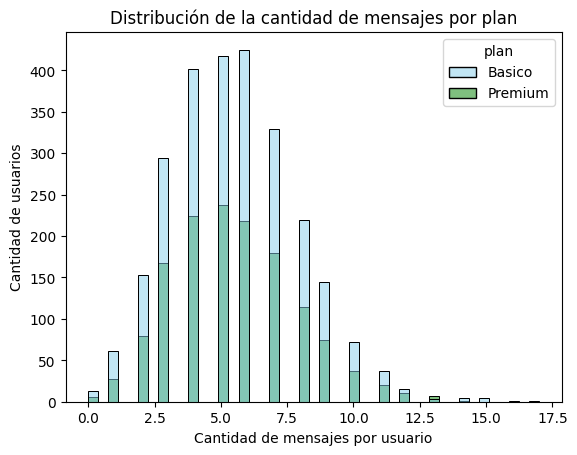

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha** (asimetría ≈ 0.46): la mayoría envía entre 4 y 7 mensajes (mediana 5) y unos pocos llegan a 17.
- **No existe ningún patrón por plan:** los usuarios Basico envían en promedio 5.53 mensajes y los Premium 5.52, con la misma mediana (5). Pagar Premium no se traduce en más mensajes.

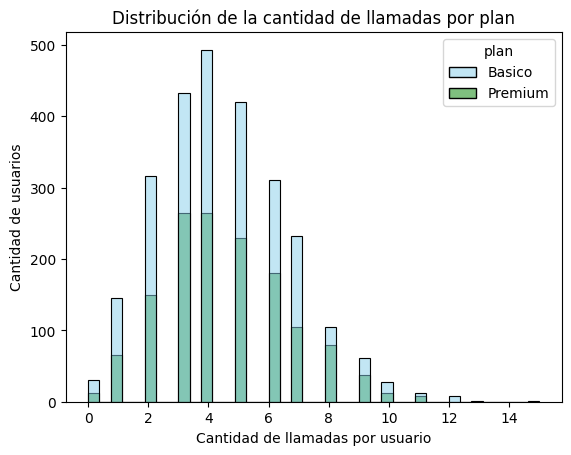

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha** (asimetría ≈ 0.50): la mayoría hace entre 3 y 6 llamadas (mediana 4) y la cola llega a 15.
- **No existe ningún patrón por plan:** Basico promedia 4.45 llamadas y Premium 4.52, con la misma mediana (4).

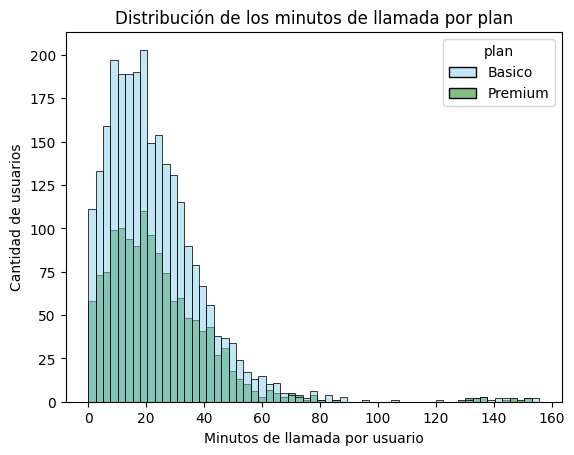

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de los minutos de llamada por plan')
plt.xlabel('Minutos de llamada por usuario')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:
- Distribución **fuertemente sesgada a la derecha** (asimetría ≈ 2.53): la mediana es de 19.78 minutos, pero la media sube a 23.31 por una cola larga que llega a 155.69 minutos. Se ve un **grupo separado entre ~120 y 156 minutos**, que corresponde a los usuarios con un evento de 120 minutos (lo reviso en 5.2).
- Diferencia mínima por plan: los Premium hablan un poco más (mediana de 20.64 minutos y media de 24.08) que los Basico (19.53 y 22.90). Es apenas ~1 minuto en 6 meses, así que **no hay un patrón relevante**.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:
 - `age`
 - `cant_mensajes`
 - `cant_llamadas`
 - `total_minutos_llamada`
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
 - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

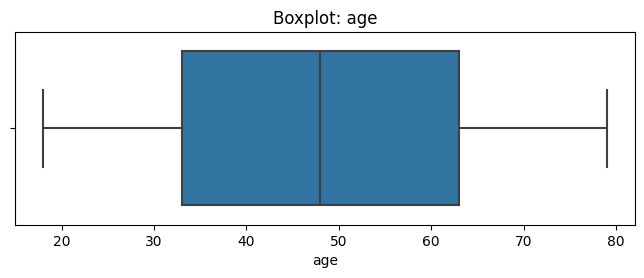

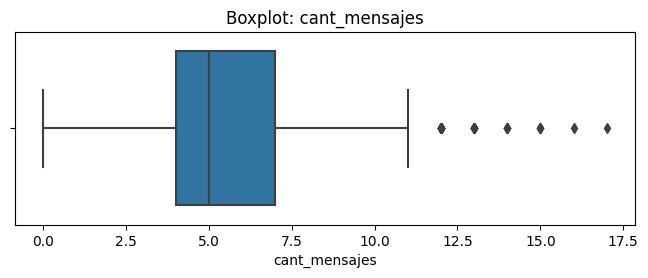

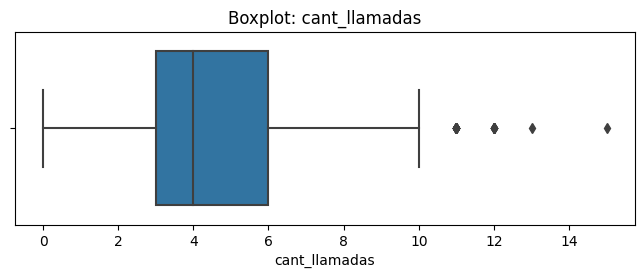

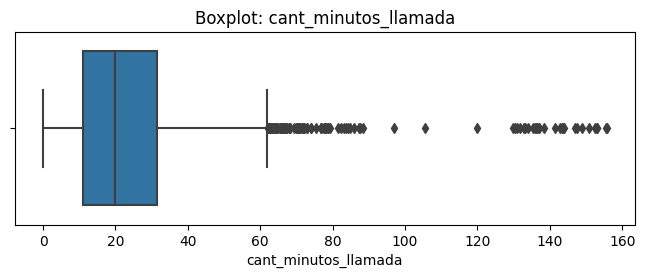

In [34]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: **no presenta outliers**. Todos los valores están entre 18 y 79 años, dentro de los bigotes.
- cant_mensajes: **sí presenta outliers, solo del lado superior** (usuarios con muchos mensajes).
- cant_llamadas: **sí presenta outliers, solo del lado superior**.
- cant_minutos_llamada: **sí presenta outliers, solo del lado superior**, y es la variable con la cola más larga.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Los outliers solo aparecen del lado superior, así que calculo solo el límite superior
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f'{col}: Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, '
          f'límite superior={limite_superior:.2f}, outliers={n_outliers} '
          f'({n_outliers / len(user_profile):.2%})')

cant_mensajes: Q1=4.00, Q3=7.00, IQR=3.00, límite superior=11.50, outliers=46 (1.15%)
cant_llamadas: Q1=3.00, Q3=6.00, IQR=3.00, límite superior=10.50, outliers=30 (0.75%)
cant_minutos_llamada: Q1=11.11, Q3=31.41, IQR=20.30, límite superior=61.87, outliers=109 (2.73%)


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: **mantener outliers**. El límite superior es 11.5 y el máximo 17: son 46 usuarios (1.15%). Enviar 17 mensajes en 6 meses es un uso real alto y posible, no un error ni un indicio de fraude.
- cant_llamadas: **mantener outliers**. El límite superior es 10.5 y el máximo 15: son 30 usuarios (0.75%). 15 llamadas en 6 meses es un uso alto pero normal.
- cant_minutos_llamada: **mantener outliers, con una alerta**. El límite superior es 61.87 y el máximo 155.69: son 109 usuarios (2.73%). 155 minutos en 6 meses (~26 min/mes) es un consumo posible, por eso no los elimino. Pero **30 de esos 109 usuarios tienen un evento de exactamente 120 minutos**, el valor repetido que vimos en 2.2 (16 de esos eventos son mensajes). Ese valor infla sus minutos y conviene validarlo con el equipo de datos como posible error de registro. Además, la suma de `duration` de la plantilla incluye los 16 mensajes con `duration` = 120, que aportan 1,920 minutos (2% del total); sin ellos, los outliers de minutos serían 96 en vez de 109. Mantengo el cálculo de la plantilla y lo dejo documentado. Para resumir los datos uso la mediana, que no se ve afectada por estos valores.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
 - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
 - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
 - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
# El orden importa: primero se evalúa 'Bajo uso', luego 'Uso medio' y el resto es 'Alto uso'
# (los conteos ya no tienen NaN porque el usuario sin actividad se rellenó con 0)
user_profile['grupo_uso'] = 'Alto uso'
user_profile.loc[(user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'grupo_uso'] = 'Uso medio'
user_profile.loc[(user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'grupo_uso'] = 'Bajo uso'

user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
 - `'Joven'` cuando age < 30
 - `'Adulto'` cuando age < 60
 - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = 'Adulto Mayor'
user_profile.loc[user_profile['age'] < 60, 'grupo_edad'] = 'Adulto'
user_profile.loc[user_profile['age'] < 30, 'grupo_edad'] = 'Joven'

user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

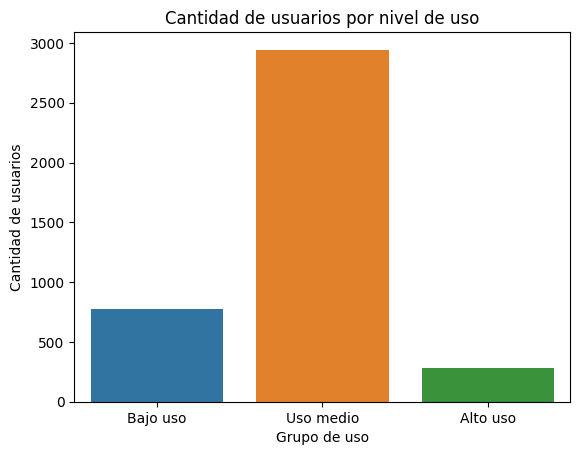

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.title('Cantidad de usuarios por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

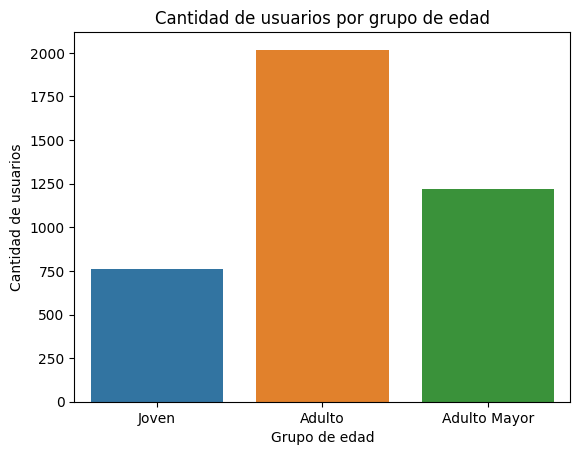

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.title('Cantidad de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [43]:
# Apoyo para el análisis ejecutivo: relación de los segmentos con el plan y el uso
print('Plan dentro de cada grupo de uso (%):')
print((pd.crosstab(user_profile['grupo_uso'], user_profile['plan'], normalize='index') * 100).round(1))
print()
print('Uso promedio por grupo de edad:')
print(user_profile.groupby('grupo_edad')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean().round(2))
print()
print('Grupo de uso dentro de cada grupo de edad (%):')
print((pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100).round(1))
print()
print('Proporción de usuarios con baja (churn_date no nulo) por grupo de uso (%):')
print((user_profile['churn_date'].notna().groupby(user_profile['grupo_uso']).mean() * 100).round(1))

Plan dentro de cada grupo de uso (%):
plan       Basico  Premium
grupo_uso                 
Alto uso     66.5     33.5
Bajo uso     65.9     34.1
Uso medio    64.5     35.5

Uso promedio por grupo de edad:
              cant_mensajes  cant_llamadas  cant_minutos_llamada
grupo_edad                                                      
Adulto                 5.55           4.48                 22.99
Adulto Mayor           5.49           4.50                 23.58
Joven                  5.52           4.43                 23.75

Grupo de uso dentro de cada grupo de edad (%):
grupo_uso     Alto uso  Bajo uso  Uso medio
grupo_edad                                 
Adulto             7.6      18.1       74.3
Adulto Mayor       6.1      21.0       72.9
Joven              6.7      20.7       72.6

Proporción de usuarios con baja (churn_date no nulo) por grupo de uso (%):
grupo_uso
Alto uso     14.0
Bajo uso     11.4
Uso medio    11.5
Name: churn_date, dtype: float64



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: 55 filas (1.38%) con el sentinel **-999**. Se reemplazaron por la mediana de las edades válidas (48 años).
- `city`: 469 nulos (11.72%) y 96 filas (2.40%) con el sentinel **`"?"`**. En total hay **565 usuarios (14.13%) sin ciudad**, que se dejaron como nulos.
- `reg_date`: **40 fechas imposibles (1.0%)** en 2026, todas el 2026-05-10. Se marcaron como nulas.
- `churn_date`: 3,534 nulos (88.35%), que corresponden a clientes activos. Los 466 valores restantes vienen como texto en notación científica con coma decimal (p. ej. `1,71832E+18`); al convertirlos resultan fechas entre junio y diciembre de 2024, posteriores al periodo de uso analizado (enero a junio de 2024). Además, **46 usuarios tienen una fecha de baja anterior a su fecha de registro** (ya sin las fechas de 2026), lo cual es imposible y es otro problema de calidad.
- `usage`: 50 eventos (0.12%) sin `date`. Además, `duration` tiene un 55.19% de nulos y `length` un 44.74%, pero son nulos estructurales (MAR): dependen del tipo de evento, así que se dejaron como nulos.
- Valores extremos sospechosos: 30 eventos con `duration` = 120 minutos (16 de ellos en mensajes) y 30 con `length` = 1,490 caracteres (12 en llamadas). Los 16 mensajes con duración suman 1,920 minutos (2% del total) a `cant_minutos_llamada`.


🔍 **Segmentos por Edad**
- **Adulto** (30–59 años): 2,018 usuarios (50.45%). **Adulto Mayor** (60 o más): 1,222 (30.55%). **Joven** (menos de 30): 760 (19.00%).
- El uso es prácticamente igual en los tres grupos: entre 5.49 y 5.55 mensajes, entre 4.43 y 4.50 llamadas y entre 22.99 y 23.75 minutos en promedio. La proporción de "Alto uso" varía poco: 7.6% en Adultos, 6.7% en Jóvenes y 6.1% en Adultos Mayores. **La edad no explica el consumo.**


📊 **Segmentos por Nivel de Uso**
- **Uso medio**: 2,943 usuarios (73.58%). **Bajo uso**: 779 (19.48%). **Alto uso**: 278 (6.95%), con 9.56 mensajes, 5.95 llamadas y 30.15 minutos en promedio.
- El plan no se relaciona con el nivel de uso: Premium representa el 34.1% del Bajo uso, el 35.5% del Uso medio y el 33.5% del Alto uso, casi igual que su peso total (35.12%). Además, el **66.5% de los usuarios de Alto uso (185) está en el plan Basico**.
- **Segmentos más valiosos:** (1) los **185 usuarios Alto uso en plan Basico**, porque son los que más consumen y son candidatos naturales para pasar a Premium; (2) los **1,405 Premium**, porque pagan más del doble (25 vs 12 USD) aunque consumen igual que los Basico, así que hay que cuidar que no se vayan. El grupo Alto uso muestra una tasa de bajas algo mayor (14.0% frente a 11.4–11.5%), pero con solo 278 usuarios (39 bajas) la diferencia no es concluyente (p ≈ 0.2); conviene monitorearla.
- **Outliers:** hay 109 usuarios (2.73%) por encima de 61.87 minutos, 46 (1.15%) por encima de 11.5 mensajes y 30 (0.75%) por encima de 10.5 llamadas. Se mantuvieron porque son consumos posibles. Pero los 30 usuarios con un evento de 120 minutos están todos entre los outliers de minutos, lo que apunta a un posible error de registro más que a fraude.


➡️ Esto sugiere que el **consumo de llamadas y mensajes es bajo y homogéneo**, y que **ni la edad ni el plan contratado lo explican**. Entre enero y junio de 2024, un usuario promedio usó ~3.9 minutos y ~0.9 mensajes al mes, muy por debajo de lo que incluye incluso el plan Basico (100 minutos y 100 mensajes). Hoy el plan Premium no se diferencia por el uso de voz y SMS.


💡 **Recomendaciones**
- **Campaña de upgrade** para los 185 usuarios Alto uso en plan Basico, y **monitorear la tasa de bajas del grupo Alto uso**.
- **Rediseñar el valor del Premium:** como sus clientes no llaman ni escriben más que los Basico, conviene diferenciarlo por datos (GB), beneficios o precio. Si no, ConnectaTel corre el riesgo de que 1,405 clientes bajen de plan o se vayan.
- **Crear un plan de entrada más económico** con menos minutos y mensajes para los 779 usuarios de Bajo uso (19.48%), y usarlo para atraer clientes sensibles al precio.
- **Ofertas sin segmentar por edad:** como el uso es igual en todas las edades, las campañas deberían segmentarse por nivel de uso y no por edad.
- **Mejorar la calidad de los datos:** capturar la ciudad (14.13% vacía), guardar `churn_date` como fecha (no en notación científica), validar que la baja no sea anterior al registro, evitar fechas por defecto como 2026-05-10 y validar los eventos de 120 minutos y 1,490 caracteres.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).
3. Sube tu notebook **Add file → Upload files**.

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.
2. Ve a **File → Save a copy in GitHub**.
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).
4. Escribe un mensaje de commit claro, por ejemplo:
 - `feat: add final ConnectaTel analysis`
 - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,
- los datasets utilizados,
- las etapas del análisis realizadas,
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: https://github.com/valercardenas10-rgb/connectatel-analysis